# Parte Específica — EDA do dataset Hepatitis C

Diagnóstico de qualidade no dado bruto (estrutura, ausentes e outliers) e análise de distribuições e relações
no dado preparado por `preparacao.py`.

Fonte: *HCV data*, UCI Machine Learning Repository (Lichtinghagen, Klawonn e Hoffmann, 2020), licença CC BY 4.0.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
import preparacao

config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

PALETA = config.CORES_CATEGORIA


def salvar(fig, nome):
    fig.savefig(config.DIR_FIGURAS / f'{nome}.png', dpi=150, bbox_inches='tight')

## 1. Visão estrutural do bruto

In [2]:
bruto = preparacao.separar_categoria(preparacao.renomear_colunas(preparacao.carregar_bruto()))
print(f'{bruto.shape[0]} linhas x {bruto.shape[1]} colunas')
bruto.head()

615 linhas x 14 colunas


,categoria,idade,sexo,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot,categoria_cod
1,Doador,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0
2,Doador,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0
3,Doador,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0
4,Doador,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0
5,Doador,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0


In [3]:
bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 615 entries, 1 to 615
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   categoria      615 non-null    str    
 1   idade          615 non-null    int64  
 2   sexo           615 non-null    str    
 3   alb            614 non-null    float64
 4   alp            597 non-null    float64
 5   alt            614 non-null    float64
 6   ast            615 non-null    float64
 7   bil            615 non-null    float64
 8   che            615 non-null    float64
 9   chol           605 non-null    float64
 10  crea           615 non-null    float64
 11  ggt            615 non-null    float64
 12  prot           614 non-null    float64
 13  categoria_cod  615 non-null    str    
dtypes: float64(10), int64(1), str(3)
memory usage: 72.4 KB


In [4]:
pd.DataFrame({
    'tipo': bruto.dtypes.astype(str),
    'n_unicos': bruto.nunique(),
    'ausentes': bruto.isna().sum(),
})

,tipo,n_unicos,ausentes
categoria,str,5,0
idade,int64,49,0
sexo,str,2,0
alb,float64,189,1
alp,float64,414,18
alt,float64,341,1
ast,float64,297,0
bil,float64,188,0
che,float64,407,0
chol,float64,313,10


In [5]:
print(f'Linhas duplicadas: {bruto.duplicated().sum()}')

tabela_cat = pd.crosstab(bruto['categoria'], bruto['sexo'], margins=True, margins_name='total')
tabela_cat['pct_total'] = (tabela_cat['total'] / len(bruto) * 100).round(1)
tabela_cat['linhas_com_ausente'] = bruto.groupby('categoria')[config.COLS_EXAMES].apply(
    lambda g: g.isna().any(axis=1).sum()
).reindex(tabela_cat.index)
tabela_cat.reindex(config.ORDEM_CATEGORIAS + ['total'])

Linhas duplicadas: 0


sexo,f,m,total,pct_total,linhas_com_ausente
categoria,,,,,
Doador,215,318,533,86.7,7.0
Doador suspeito,1,6,7,1.1,0.0
Hepatite,4,20,24,3.9,4.0
Fibrose,8,13,21,3.4,9.0
Cirrose,10,20,30,4.9,6.0
total,238,377,615,100.0,NaN


In [6]:
bruto[config.COLS_QUANTITATIVAS].describe().T.assign(
    assimetria=bruto[config.COLS_QUANTITATIVAS].skew()
).round(2)

,count,mean,std,min,25%,50%,75%,max,assimetria
idade,615.0,47.41,10.06,19.00,39.00,47.00,54.00,77.00,0.27
alb,614.0,41.62,5.78,14.90,38.80,41.95,45.20,82.20,-0.18
alp,597.0,68.28,26.03,11.30,52.50,66.20,80.10,416.60,4.65
alt,614.0,28.45,25.47,0.90,16.40,23.00,33.08,325.30,5.51
ast,615.0,34.79,33.09,10.60,21.60,25.90,32.90,324.00,4.94
bil,615.0,11.40,19.67,0.80,5.30,7.30,11.20,254.00,8.39
che,615.0,8.20,2.21,1.42,6.94,8.26,9.59,16.41,-0.11
chol,605.0,5.37,1.13,1.43,4.61,5.30,6.06,9.67,0.38
crea,615.0,81.29,49.76,8.00,67.00,77.00,88.00,1079.10,15.17
ggt,615.0,39.53,54.66,4.50,15.70,23.30,40.20,650.90,5.63


**Análise do grupo:**

A base possui 615 linhas e 14 colunas: 13 vêm do arquivo original e `categoria_cod` foi criada a partir de `Category`. Cada linha representa uma pessoa: doador de sangue ou paciente. Das variáveis originais, 11 são quantitativas (idade, ALB, ALP, ALT, AST, BIL, CHE, CHOL, CREA, GGT e PROT) e 2 são qualitativas (sexo e categoria). A idade é numérica discreta, enquanto as outras dez quantitativas são medidas laboratoriais. Foram identificados 31 valores ausentes em 26 linhas, e ALP é a variável com mais ausências, 18 no total. Não há linhas duplicadas. A variável categoria está fortemente desbalanceada: são 533 doadores de sangue, 7 doadores suspeitos, 24 pacientes com hepatite, 21 com fibrose e 30 com cirrose.

**Decisão sobre os doadores suspeitos:**

Manteremos os sete doadores suspeitos como uma categoria separada.

O motivo é preservar a classificação original e permitir a análise de seus perfis, que apresentam diferenças em relação aos doadores comuns. Por exemplo, a mediana de GGT é 83 entre os suspeitos e 21,4 entre os doadores comuns.

Devido ao tamanho reduzido do grupo, apresentaremos contagens junto aos percentuais. Cada participante representa aproximadamente 14,3 pontos percentuais nessa categoria.

## 2. Ausentes e mecanismo de ausência

Para investigar o mecanismo (MCAR, MAR ou MNAR), o indicador de ausência de cada exame é cruzado com
o diagnóstico, o sexo, a idade e os demais exames.

In [7]:
cols_com_ausente = [c for c in config.COLS_EXAMES if bruto[c].isna().any()]
ausente = bruto[cols_com_ausente].isna()

print(f'{int(ausente.sum().sum())} células ausentes em {int(ausente.any(axis=1).sum())} linhas '
      f'({ausente.any(axis=1).mean():.1%} das linhas)')
ausente.sum().to_frame('n_ausentes')

31 células ausentes em 26 linhas (4.2% das linhas)


,n_ausentes
alb,1
alp,18
alt,1
chol,10
prot,1


In [8]:
print('Linhas com mais de um exame ausente:')
bruto.loc[ausente.sum(axis=1) > 1, ['categoria', 'sexo', 'idade'] + cols_com_ausente]

Linhas com mais de um exame ausente:


,categoria,sexo,idade,alb,alp,alt,chol,prot
585,Fibrose,f,75,36.0,NaN,114.0,NaN,72.0
591,Cirrose,m,46,20.0,NaN,62.0,NaN,NaN
604,Cirrose,m,65,NaN,NaN,40.0,NaN,79.0


### Ausência × diagnóstico

In [9]:
contagem = ausente.groupby(bruto['categoria']).sum().reindex(config.ORDEM_CATEGORIAS)
contagem['n_linhas'] = bruto['categoria'].value_counts().reindex(config.ORDEM_CATEGORIAS)
contagem

,alb,alp,alt,chol,prot,n_linhas
categoria,,,,,,
Doador,0,0,0,7,0,533
Doador suspeito,0,0,0,0,0,7
Hepatite,0,3,1,0,0,24
Fibrose,0,9,0,1,0,21
Cirrose,1,6,0,2,1,30


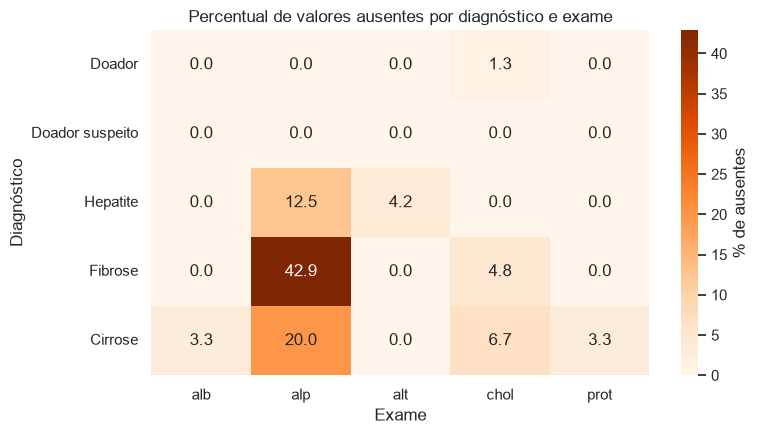

In [10]:
pct = ausente.groupby(bruto['categoria']).mean().reindex(config.ORDEM_CATEGORIAS) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pct, annot=True, fmt='.1f', cmap='Oranges', ax=ax, cbar_kws={'label': '% de ausentes'})
ax.set_title('Percentual de valores ausentes por diagnóstico e exame')
ax.set_xlabel('Exame')
ax.set_ylabel('Diagnóstico')
fig.tight_layout()
salvar(fig, 'eda_ausentes_por_diagnostico')
plt.show()

### Ausência × sexo e idade

In [11]:
pd.concat({
    'ausentes_por_sexo': ausente.groupby(bruto['sexo']).sum().T,
    'pct_por_sexo': (ausente.groupby(bruto['sexo']).mean().T * 100).round(1),
}, axis=1)

ausentes_por_sexo     pct_por_sexo     
sexo                 f   m            f    m
alb                  0   1          0.0  0.3
alp                  6  12          2.5  3.2
alt                  0   1          0.0  0.3
chol                 7   3          2.9  0.8
prot                 0   1          0.0  0.3

In [12]:
linhas = []
for col in cols_com_ausente:
    idades = bruto.groupby(ausente[col])['idade']
    linhas.append({
        'exame': col,
        'idade_media_com_valor': idades.mean().get(False),
        'idade_media_ausente': idades.mean().get(True),
        'n_ausente': int(ausente[col].sum()),
    })
pd.DataFrame(linhas).set_index('exame').round(1)

,idade_media_com_valor,idade_media_ausente,n_ausente
exame,,,
alb,47.4,65.0,1
alp,47.4,49.0,18
alt,47.4,38.0,1
chol,47.4,49.3,10
prot,47.4,46.0,1


### Ausência × demais exames

Mediana dos outros exames nas linhas em que o exame da linha está ausente, comparada com as linhas em que ele foi medido.

In [13]:
comparacoes = {}
for col in cols_com_ausente:
    outros = [c for c in config.COLS_EXAMES if c != col]
    medianas = bruto.groupby(ausente[col])[outros].median().T
    medianas.columns = medianas.columns.map({False: 'medido', True: 'ausente'})
    comparacoes[col] = medianas
pd.concat(comparacoes, axis=1).round(2)

alb            alp            alt           chol           prot  \
alb  medido ausente medido ausente medido ausente medido ausente medido   
alp   66.20     NaN    NaN     NaN  66.25   56.30  66.20   93.30  66.20   
alt   23.00    40.0  22.50   90.50    NaN     NaN  23.00   17.15  23.00   
ast   25.90    54.0  25.70   64.50  25.90   33.10  25.80   39.30  25.90   
bil    7.30    13.0   7.10   13.50   7.30    7.00   7.30    4.95   7.30   
che    8.26     7.5   8.27    7.65   8.26    9.58   8.26    8.30   8.26   
chol   5.30     NaN   5.31    4.20   5.30    6.00    NaN     NaN   5.30   
crea  77.00    70.0  77.00   72.00  76.85   77.90  77.00   63.00  76.85   
ggt   23.30   107.0  22.90   75.50  23.30   18.90  23.20   27.35  23.30   
prot  72.20    79.0  72.10   77.00  72.20   63.00  72.20   72.40    NaN   
alb     NaN     NaN  42.00   39.00  41.90   45.00  41.90   45.60  42.00   

              
alb  ausente  
alp      NaN  
alt    62.00  
ast   113.00  
bil   254.00  
che     1.48  
chol     NaN  
crea  114.00  
ggt   138.00  
prot     NaN  
alb    20.00

**Análise dos valores ausentes:**

Foram identificadas 31 células ausentes em 26 participantes, correspondendo a aproximadamente 4,2% dos 615 registros. As ausências estão distribuídas em cinco exames:

* ALB — 1 valor ausente.
* ALP — 18 valores ausentes.
* ALT — 1 valor ausente.
* CHOL — 10 valores ausentes.
* PROT — 1 valor ausente.

A ausência de ALP apresenta diferenças importantes entre as categorias. Não há ausências desse exame entre os 533 doadores comuns, enquanto existem três entre os 24 registros de hepatite, nove entre os 21 de fibrose e seis entre os 30 de cirrose. Isso corresponde, respectivamente, a 12,5%, 42,9% e 20% desses três grupos.

Os participantes sem ALP também apresentam diferenças em outros exames. A mediana de AST é aproximadamente 64,5 entre os registros sem ALP e 25,7 entre aqueles com ALP observado. Para GGT, as medianas são 75,5 e 22,9, respectivamente.

Esses resultados indicam associação da ausência com características observadas. Adotaremos MAR como hipótese operacional, reconhecendo que a causa do mecanismo de ausência permanece indeterminada com as informações disponíveis.

**Decisão sobre os ausentes:**

Utilizaremos imputação por KNN com cinco vizinhos, após padronizar a idade e os dez exames.

O motivo é estimar os valores ausentes a partir de participantes semelhantes nas características observadas, preservando os registros e considerando diferenças entre os perfis laboratoriais.

As regras adotadas serão:

* Utilizar idade e exames no cálculo das distâncias.
* Excluir `categoria`, `categoria_cod` e as variáveis discretizadas da imputação.
* Preservar os indicadores que identificam quais valores eram originalmente ausentes.
* Diferenciar, na documentação, valores observados e imputados.
* Em uma avaliação preditiva, ajustar o padronizador e o imputador apenas nos dados de treinamento.

A escolha do KNN é fundamentada na estrutura observada, mas sua superioridade sobre outros imputadores ainda não foi testada. A mediana global poderia representar mal alguns perfis, enquanto a imputação por diagnóstico utilizaria a variável-alvo para preencher as entradas de uma eventual classificação.

**Ausência de CHOL e ausentes únicos:**

| Categoria | Ausentes/total | Taxa |
|---|---:|---:|
| Doadores | 7/533 | 1,31% |
| Suspeitos | 0/7 | 0% |
| Hepatite | 0/24 | 0% |
| Fibrose | 1/21 | 4,76% |
| Cirrose | 2/30 | 6,67% |

O padrão é diferente do de ALP. ALP tem ausência concentrada nos três grupos com doença e nenhum ausente entre doadores. CHOL tem sete ausências entre doadores, mas taxas maiores em fibrose e cirrose. As contagens absolutas e as taxas levam a leituras diferentes.

MAR pode ser mantida como hipótese operacional, com evidência limitada. Além das diferenças por diagnóstico:

- A ausência é de 7/238 entre mulheres, 2,94%, e 3/377 entre homens, 0,80%.
- A idade média é 49,3 anos entre os dez ausentes e 47,4 entre os demais.
- A mediana de AST é 39,3 entre os ausentes e 25,8 entre os demais.

Essas diferenças são compatíveis com associação a variáveis observadas, mas dez ausências oferecem pouca base para identificar o mecanismo. MNAR continua sendo uma possibilidade não resolvida pelos dados.

Há apenas uma ausência em ALB, ALT e PROT, quantidade insuficiente para estabelecer um padrão:

- ALB: participante com cirrose, também sem ALP e CHOL.
- ALT: participante com hepatite, sem outros exames ausentes.
- PROT: participante com cirrose, também sem ALP e CHOL.

ALB e PROT faltam em pessoas diferentes.

**Adequação do KNN:** continua sendo uma estratégia inicial razoável, mas a adequação por exame ainda precisa de avaliação. ALP merece maior cautela, pois 42,9% dos registros de fibrose estão ausentes. Além disso, o predomínio de doadores e os extremos podem influenciar os vizinhos escolhidos.

Para avaliar a qualidade da imputação, é necessário ocultar valores conhecidos e comparar as estimativas, considerando exame e diagnóstico. A simples eliminação dos NaN não valida o método.

AST, GGT, BIL e CHE estão completos no bruto. Portanto, os achados centrais das explanatórias utilizam valores originalmente observados.

## 3. Outliers

In [14]:
def resumo_outliers(dados, cols):
    linhas = []
    for col in cols:
        q1, q3 = dados[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        fora = (dados[col] < q1 - 1.5 * iqr) | (dados[col] > q3 + 1.5 * iqr)
        z = (dados[col] - dados[col].mean()) / dados[col].std()
        linhas.append({
            'variavel': col,
            'mediana': dados[col].median(),
            'maximo': dados[col].max(),
            'lim_inf_iqr': q1 - 1.5 * iqr,
            'lim_sup_iqr': q3 + 1.5 * iqr,
            'n_iqr': int(fora.sum()),
            'n_z_maior_3': int((z.abs() > 3).sum()),
        })
    return pd.DataFrame(linhas).set_index('variavel').round(2)


tabela_outliers = resumo_outliers(bruto, config.COLS_QUANTITATIVAS)
tabela_outliers

,mediana,maximo,lim_inf_iqr,lim_sup_iqr,n_iqr,n_z_maior_3
variavel,,,,,,
idade,47.00,77.00,16.50,76.50,1,0
alb,41.95,82.20,29.20,54.80,27,13
alp,66.20,416.60,11.10,121.50,10,3
alt,23.00,325.30,-8.61,58.09,36,10
ast,25.90,324.00,4.65,49.85,64,14
bil,7.30,254.00,-3.55,20.05,47,7
che,8.26,16.41,2.95,13.57,24,9
chol,5.30,9.67,2.44,8.24,12,7
crea,77.00,1079.10,35.50,119.50,12,3


### Em quais diagnósticos estão os outliers (regra de 1,5 × IQR)

In [15]:
fora_iqr = pd.DataFrame({
    col: (bruto[col] < tabela_outliers.loc[col, 'lim_inf_iqr'])
         | (bruto[col] > tabela_outliers.loc[col, 'lim_sup_iqr'])
    for col in config.COLS_EXAMES
})
fora_iqr.groupby(bruto['categoria']).sum().reindex(config.ORDEM_CATEGORIAS)

,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
categoria,,,,,,,,,,
Doador,13,4,19,10,23,7,9,2,29,8
Doador suspeito,6,2,3,3,0,1,0,4,4,6
Hepatite,0,0,3,11,4,2,1,1,7,2
Fibrose,0,0,7,15,2,0,0,0,9,0
Cirrose,8,4,4,25,18,14,2,5,16,4


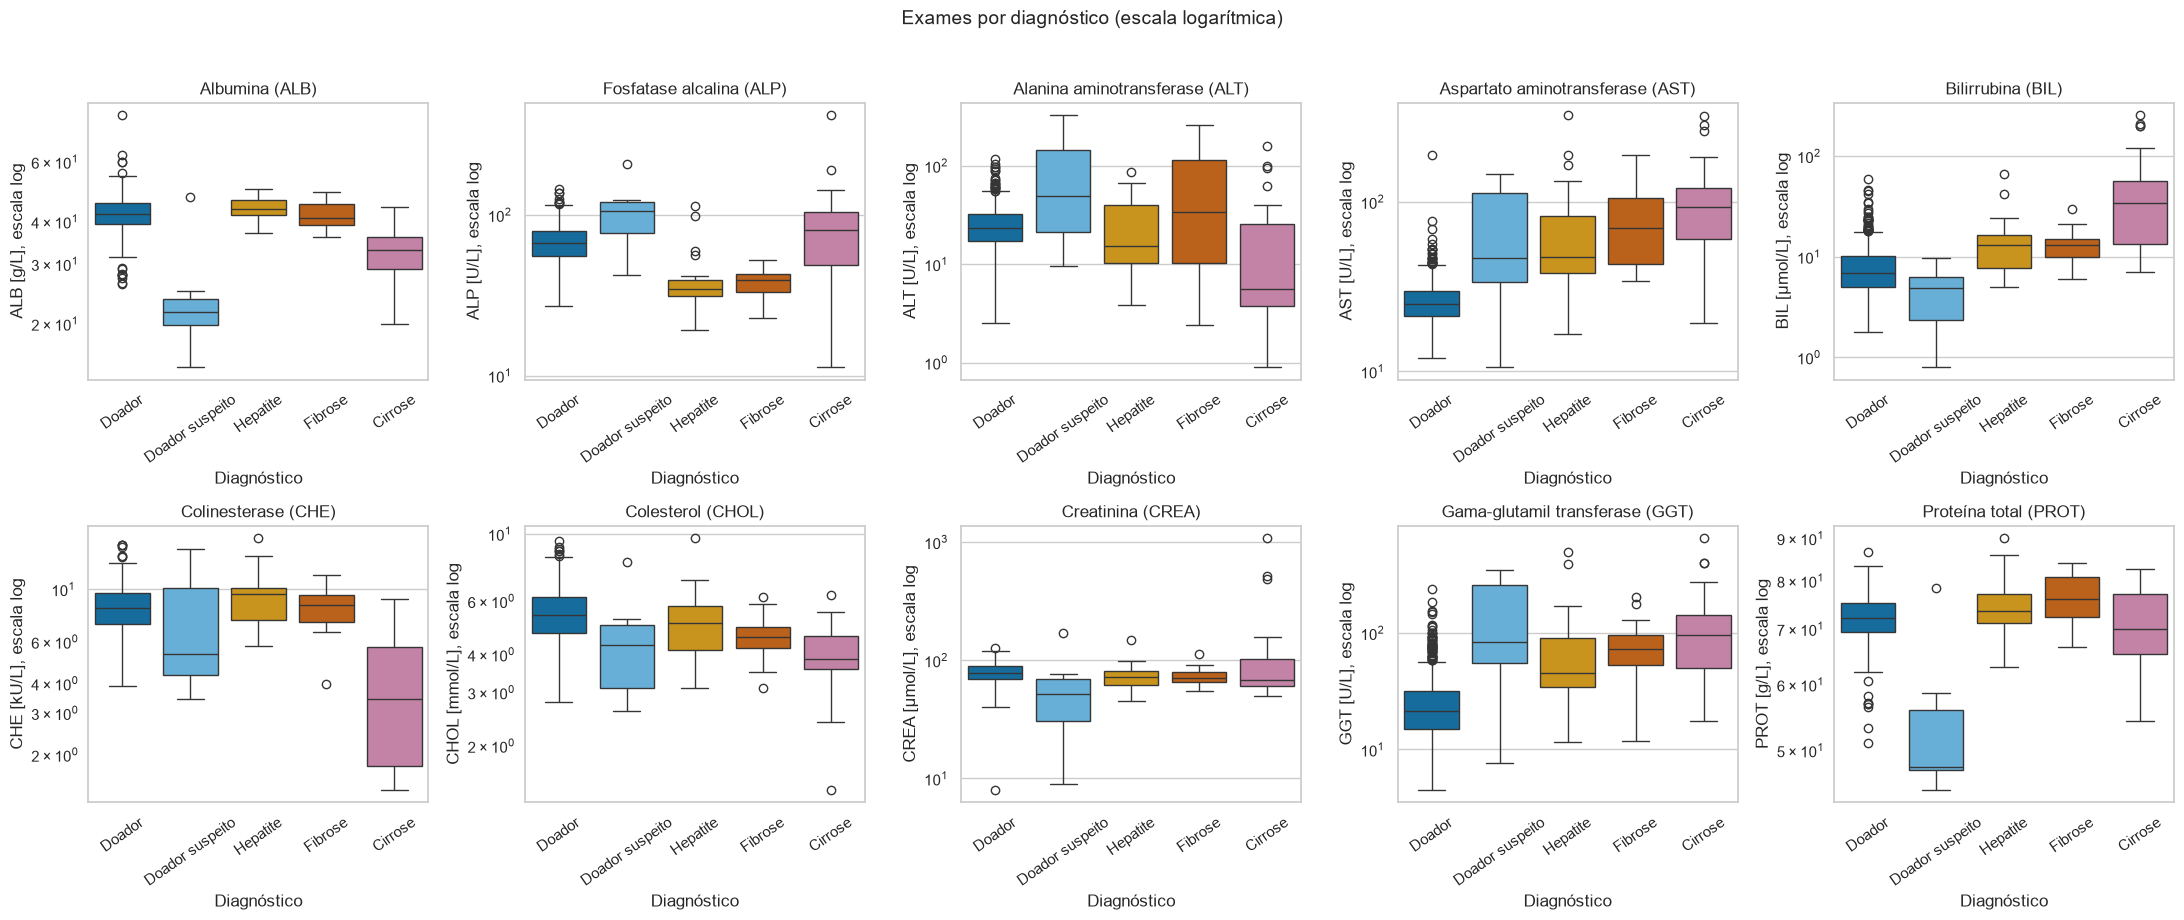

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, col in zip(axes.flat, config.COLS_EXAMES):
    sns.boxplot(data=bruto, x='categoria', y=col, hue='categoria', order=config.ORDEM_CATEGORIAS,
                hue_order=config.ORDEM_CATEGORIAS, palette=PALETA, legend=False, ax=ax)
    ax.set_yscale('log')
    ax.set_title(config.NOMES[col])
    ax.set_xlabel('Diagnóstico')
    ax.set_ylabel(f'{col.upper()} [{config.UNIDADES[col]}], escala log')
    ax.tick_params(axis='x', rotation=35)
fig.suptitle('Exames por diagnóstico (escala logarítmica)', fontsize=14, y=1.02)
fig.tight_layout()
salvar(fig, 'eda_exames_por_diagnostico_log')
plt.show()

In [17]:
print('Valores mais extremos de cada exame (5 maiores):')
pd.concat({
    col: bruto.nlargest(5, col)[['categoria', col]].reset_index(drop=True)
    for col in config.COLS_EXAMES
}, axis=1)

Valores mais extremos de cada exame (5 maiores):


alb                    alp                     alt              ast  \
  categoria   alb        categoria    alp        categoria    alt categoria   
0    Doador  82.2          Cirrose  416.6  Doador suspeito  325.3  Hepatite   
1    Doador  62.9  Doador suspeito  208.2          Fibrose  258.0   Cirrose   
2    Doador  59.8          Cirrose  190.7  Doador suspeito  208.8   Cirrose   
3    Doador  59.7           Doador  145.0          Fibrose  164.0   Cirrose   
4    Doador  55.4          Cirrose  143.1          Cirrose  159.0    Doador   

               bil              che             chol                   crea  \
     ast categoria    bil categoria    che categoria  chol        categoria   
0  324.0   Cirrose  254.0  Hepatite  16.41  Hepatite  9.67          Cirrose   
1  319.8   Cirrose  209.0    Doador  15.43    Doador  9.43          Cirrose   
2  285.8   Cirrose  200.0    Doador  15.40    Doador  9.03          Cirrose   
3  263.1   Cirrose  200.0    Doador  15.40    Doador  8.89  Doador suspeito   
4  188.7   Cirrose  119.0    Doador  15.10    Doador  8.80          Cirrose   

                ggt             prot        
     crea categoria    ggt categoria  prot  
0  1079.1   Cirrose  650.9  Hepatite  90.0  
1   519.0  Hepatite  491.0    Doador  86.5  
2   485.9   Cirrose  400.3  Hepatite  86.0  
3   170.0   Cirrose  399.5   Fibrose  84.0  
4   158.2  Hepatite  392.2    Doador  83.4

**Análise dos outliers:**

Foram utilizados a regra de 1,5 × IQR e o critério de z-score absoluto superior a três. Os métodos sinalizaram quantidades diferentes de observações, evidenciando que a identificação depende do critério adotado.

Pelo IQR, foram sinalizados 65 valores de GGT, 64 de AST e 47 de bilirrubina. Os extremos apresentam concentração em determinadas categorias. Entre os 30 registros de cirrose, 25 foram sinalizados em AST e 18 em bilirrubina.

Como os critérios foram calculados sobre a amostra completa, dominada por doadores, parte das diferenças dos grupos menores aparece como valor extremo em relação à distribuição global.

**Decisão sobre os outliers:**

Manteremos os valores originais, sem aplicar limitação por percentis.

O motivo é preservar possíveis diferenças informativas entre as categorias, pois a exploração não identificou evidência suficiente de erro de registro ou medição para justificar a alteração automática.

Os gráficos utilizarão escala logarítmica quando necessária, mantendo medianas, intervalos interquartis e pontos individuais visíveis. Essa escolha melhora a visualização sem modificar os valores armazenados.

**Todos os exames — quantos valores cada método marca:**

| Exame | IQR | \|z\| > 3 |
|---|---:|---:|
| ALB | 27 | 13 |
| ALP | 10 | 3 |
| ALT | 36 | 10 |
| AST | 64 | 14 |
| BIL | 47 | 7 |
| CHE | 24 | 9 |
| CHOL | 12 | 7 |
| CREA | 12 | 3 |
| GGT | 65 | 10 |
| PROT | 20 | 9 |

O IQR utiliza quartis e sinaliza valores afastados da região central. O z-score utiliza média e desvio-padrão. Em distribuições assimétricas, os extremos podem aumentar o desvio-padrão e reduzir quantos valores ultrapassam três desvios. Os critérios medem afastamento estatístico, sem determinar a origem do valor.

**Concentração por diagnóstico** (contagens pelo IQR, calculado sobre a base completa):

| Exame | Doadores (533) | Suspeitos (7) | Hepatite (24) | Fibrose (21) | Cirrose (30) |
|---|---:|---:|---:|---:|---:|
| ALB | 13 | 6 | 0 | 0 | 8 |
| ALP | 4 | 2 | 0 | 0 | 4 |
| ALT | 19 | 3 | 3 | 7 | 4 |
| AST | 10 | 3 | 11 | 15 | 25 |
| BIL | 23 | 0 | 4 | 2 | 18 |
| CHE | 7 | 1 | 2 | 0 | 14 |
| CHOL | 9 | 0 | 1 | 0 | 2 |
| CREA | 2 | 4 | 1 | 0 | 5 |
| GGT | 29 | 4 | 7 | 9 | 16 |
| PROT | 8 | 6 | 2 | 0 | 4 |

As taxas precisam acompanhar essas contagens. Em AST, são 83,3% dos participantes com cirrose, 71,4% dos de fibrose e 1,9% dos doadores. Para GGT, os 29 doadores representam 5,4%, enquanto os 16 participantes com cirrose representam 53,3%.

**Plausibilidade.** A EDA não permite validar clinicamente todos os valores sinalizados. Extremos como ALB de 82,2, CREA de 8 e CREA de 1.079,1 merecem conferência das unidades, do registro original e do contexto de coleta.

Entretanto, CREA próximo de 1.079 µmol/L já foi documentado em caso clínico, mostrando que essa ordem de grandeza pode ocorrer. Isso sustenta a plausibilidade da magnitude, sem confirmar a validade dos registros desta base.

A conclusão deve ser que a validade individual dos extremos permanece não verificada. Sua manutenção é uma decisão analítica documentada.

**Os três maiores valores de CREA.** Todos pertencem a participantes classificados com cirrose. Pelo critério estatístico global:

| CREA | Outros valores sinalizados pelo IQR |
|---:|---|
| 1.079,1 | GGT de 105,6 |
| 519,0 | ALP de 137,8, GGT de 133,4 e PROT de 57,5 |
| 485,9 | ALP de 190,7, GGT de 112 e PROT de 58,5 |

Há desvios em outros exames, especialmente nos dois últimos registros. Isso é compatível com perfis multivariados extremos, mas não distingue definitivamente caso real de erro. Essa distinção exigiria documentação da coleta, repetição do exame ou validação na fonte.

**Outliers entre doadores.** Eles enfraquecem o argumento de que todo extremo seria explicado pelo diagnóstico de doença hepática. Também mostram que o rótulo “doador” não garante ausência de valores fora do padrão estatístico.

O dataset não fornece contexto suficiente para explicar esses casos. A justificativa adequada é preservar os valores por falta de confirmação de erro, registrando a incerteza. A interpretação clínica de exames alterados exige contexto e avaliação adicional.

**Efeito nos gráficos.** Manter os outliers muda os gráficos. Eles ampliam a extensão dos eixos, evidenciam caudas e podem esconder a concentração central em escala linear. A escala logarítmica melhora a leitura desse conjunto. Medianas e quartis são menos sensíveis aos extremos, mas a amplitude e os pontos individuais continuam mostrando sua presença.

No KNN, os extremos também podem afetar a padronização e as distâncias.

## 4. Distribuições no dado preparado

In [18]:
df = preparacao.carregar_tratado()
QUALITATIVAS = preparacao.colunas_qualitativas(df)

print(f'{len(df)} linhas; ausentes restantes nos exames: {int(df[config.COLS_EXAMES].isna().sum().sum())}')
print('Variáveis qualitativas:', QUALITATIVAS)

615 linhas; ausentes restantes nos exames: 0
Variáveis qualitativas: ['categoria', 'sexo', 'faixa_etaria', 'ggt_nivel']


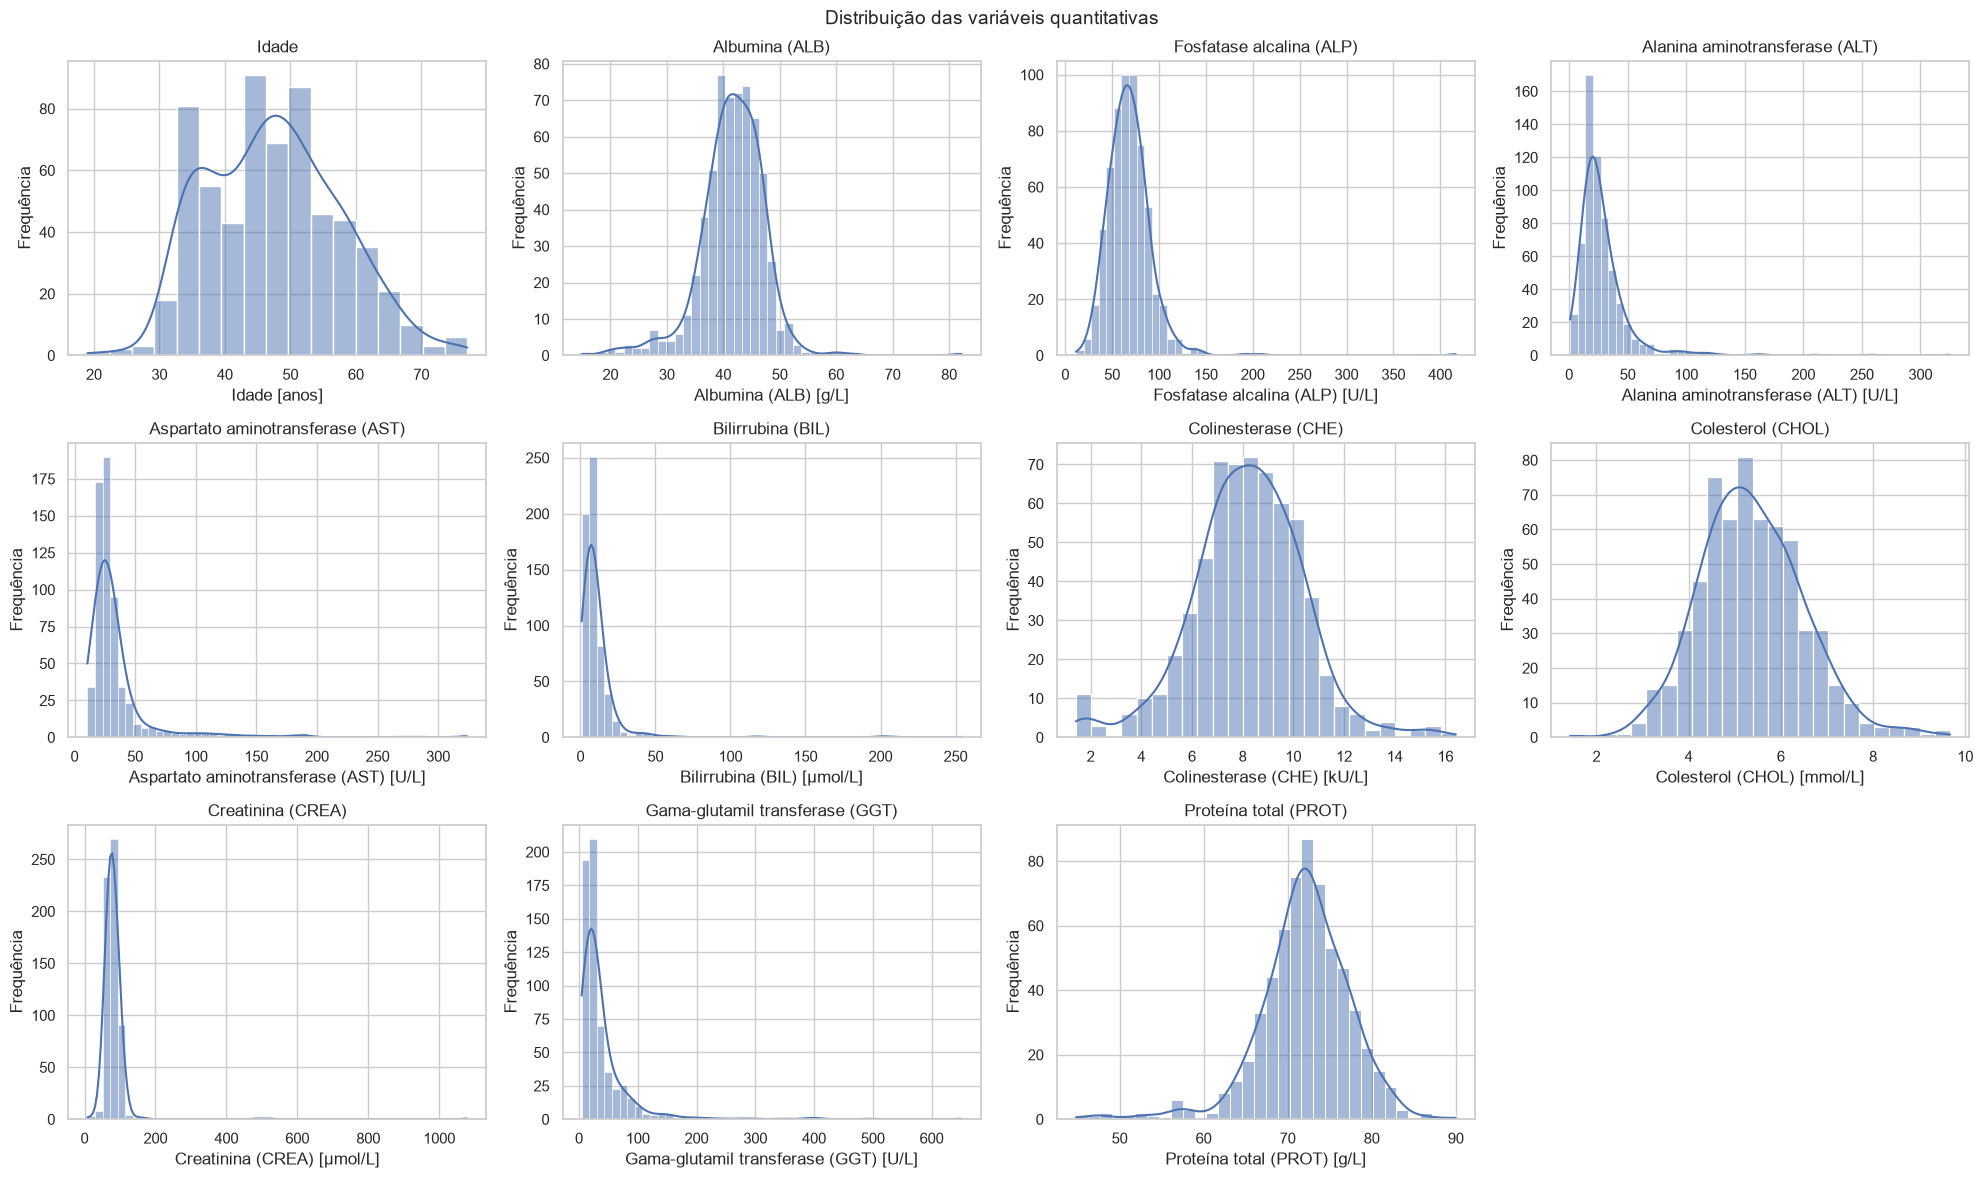

In [19]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.flat, config.COLS_QUANTITATIVAS):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(config.NOMES[col])
    ax.set_xlabel(config.rotulo(col))
    ax.set_ylabel('Frequência')
for ax in axes.flat[len(config.COLS_QUANTITATIVAS):]:
    ax.set_visible(False)
fig.suptitle('Distribuição das variáveis quantitativas', fontsize=14)
fig.tight_layout()
salvar(fig, 'eda_hist_quantitativas')
plt.show()

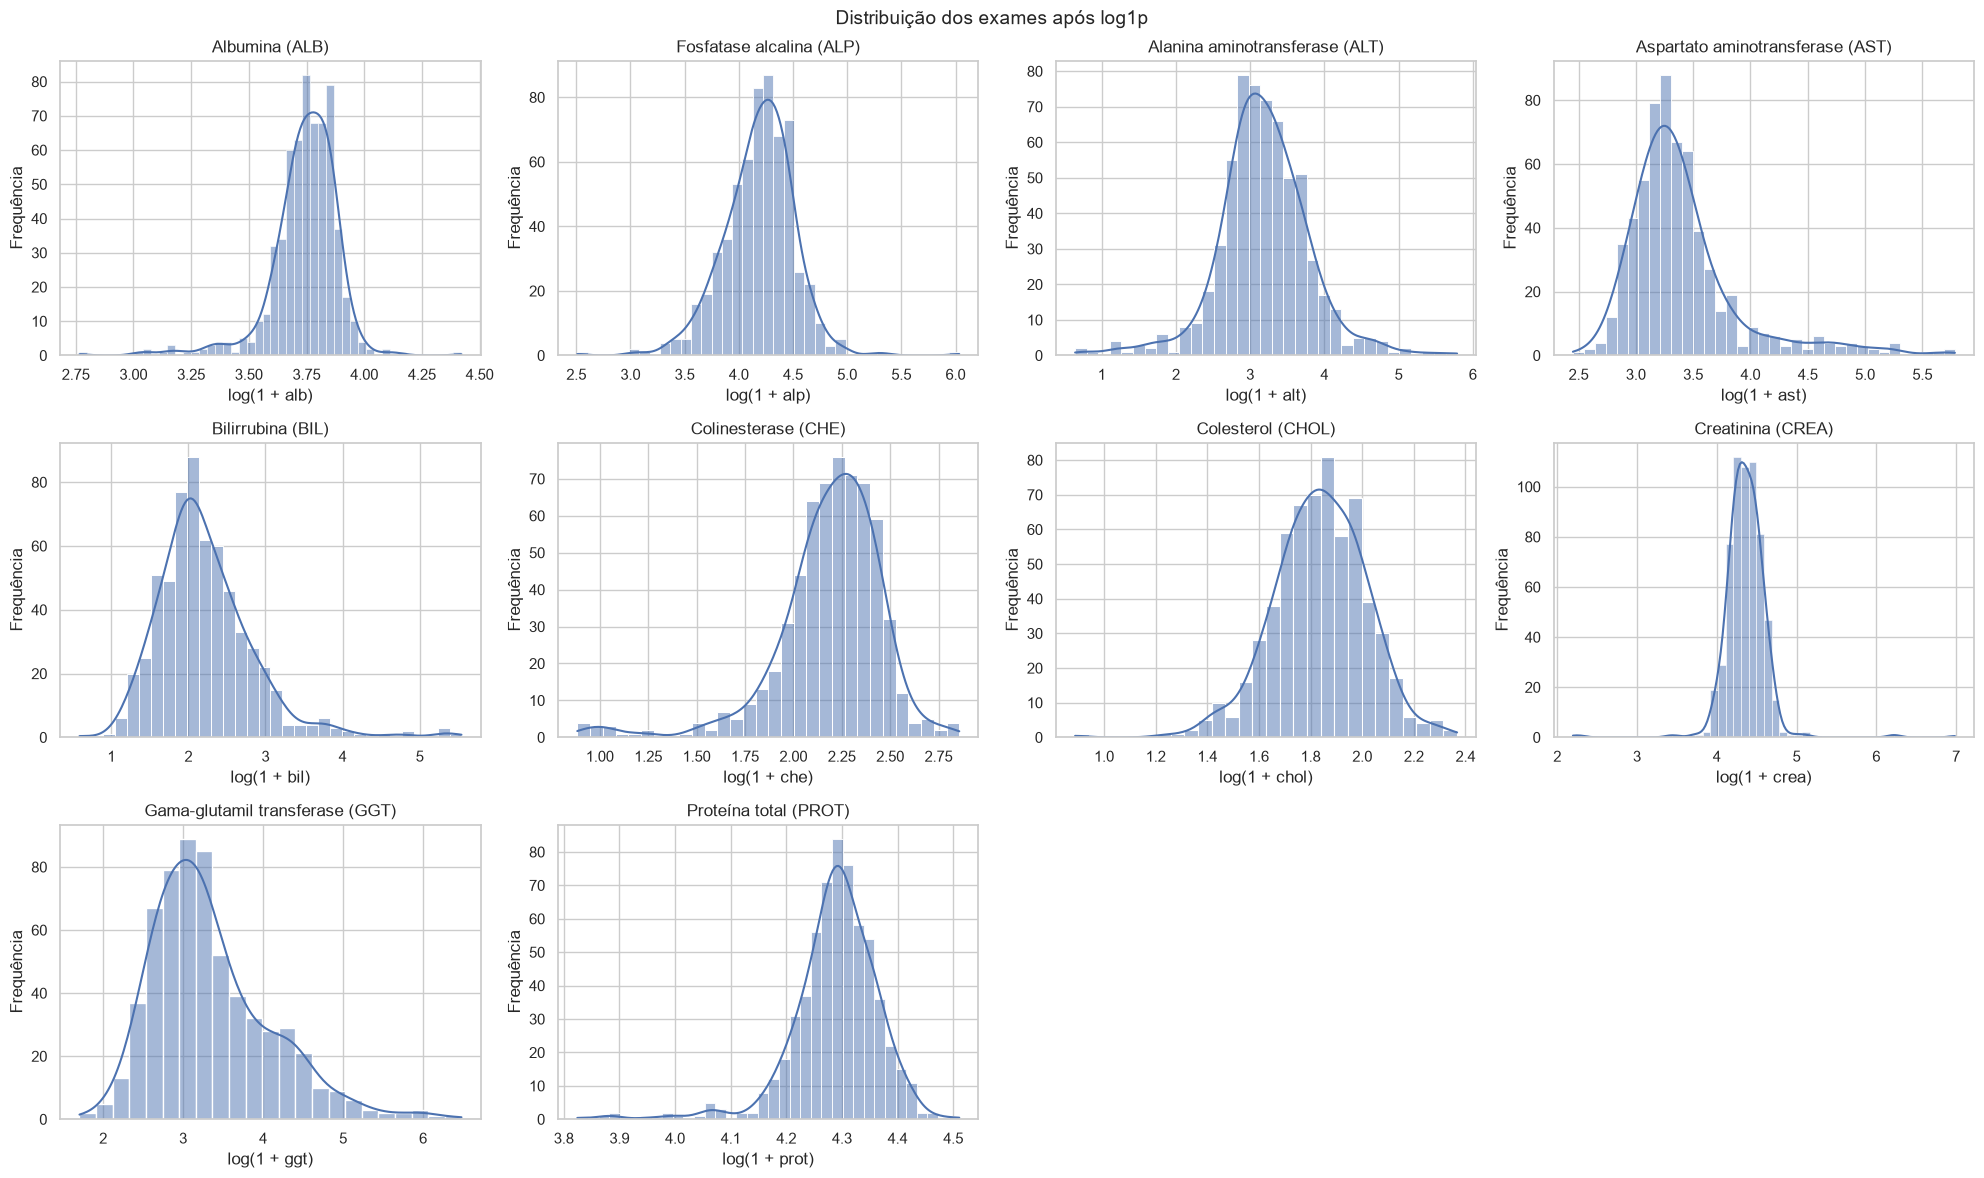

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.flat, config.COLS_EXAMES):
    sns.histplot(np.log1p(df[col]), kde=True, ax=ax)
    ax.set_title(config.NOMES[col])
    ax.set_xlabel(f'log(1 + {col})')
    ax.set_ylabel('Frequência')
for ax in axes.flat[len(config.COLS_EXAMES):]:
    ax.set_visible(False)
fig.suptitle('Distribuição dos exames após log1p', fontsize=14)
fig.tight_layout()
salvar(fig, 'eda_hist_exames_log')
plt.show()

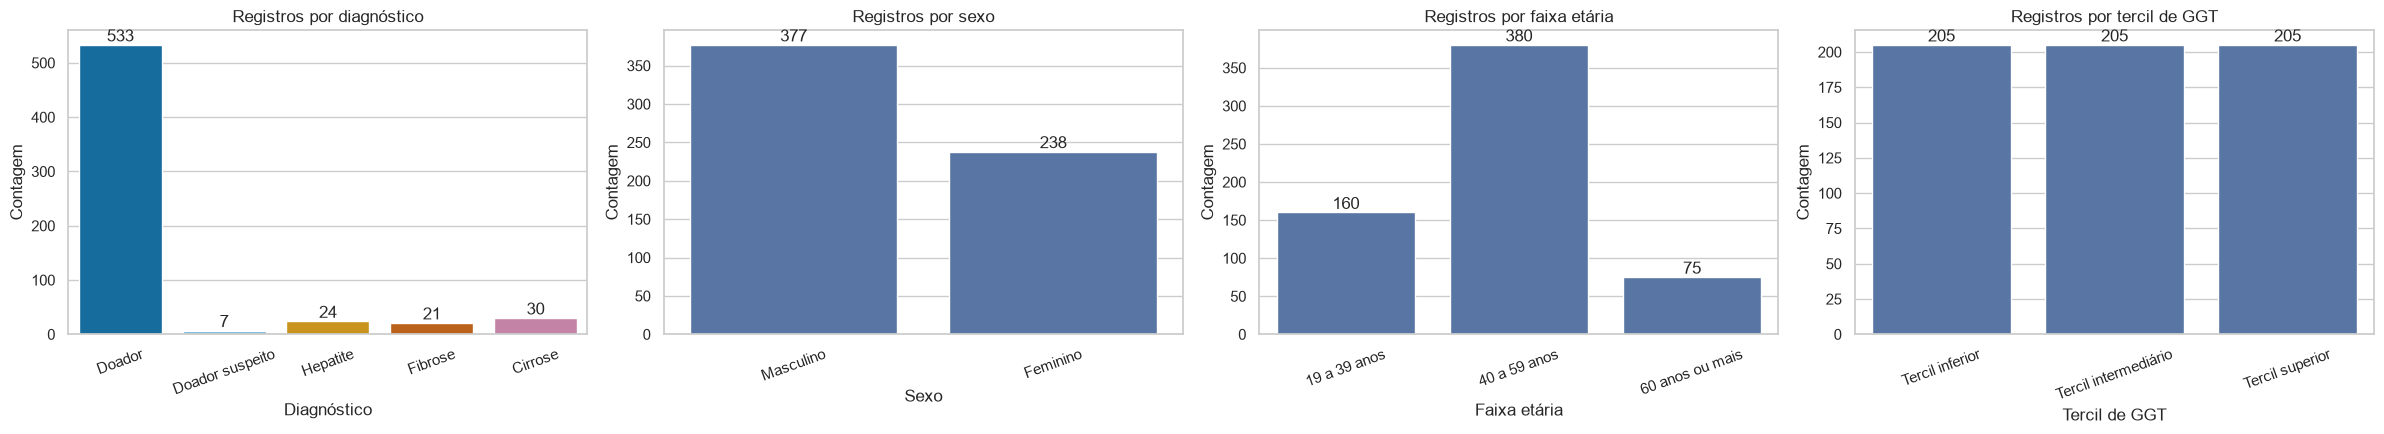

In [21]:
fig, axes = plt.subplots(1, len(QUALITATIVAS), figsize=(6 * len(QUALITATIVAS), 4.5), squeeze=False)
for ax, col in zip(axes.flat, QUALITATIVAS):
    contagem = df[col].value_counts().reindex(df[col].cat.categories)
    rotulos = [config.ROTULOS_SEXO.get(v, v) for v in contagem.index] if col == 'sexo' else contagem.index
    paleta = PALETA if col == 'categoria' else None
    sns.barplot(x=rotulos, y=contagem.values, hue=rotulos if paleta else None, palette=paleta, legend=False, ax=ax)
    for barras in ax.containers:
        ax.bar_label(barras)
    nome = config.rotulo(col)
    ax.set_title(f'Registros por {nome[0].lower() + nome[1:]}')
    ax.set_xlabel(config.rotulo(col))
    ax.set_ylabel('Contagem')
    ax.tick_params(axis='x', rotation=20)
fig.tight_layout()
salvar(fig, 'eda_contagem_qualitativas')
plt.show()

### Variáveis discretizadas

Novas qualitativas criadas a partir de quantitativas, conforme `DISCRETIZACOES` em `preparacao.py`.
`pd.cut` usa limites fixos; `pd.qcut` cria grupos de tamanho igual, com limites que dependem da amostra.

In [22]:
if not preparacao.DISCRETIZACOES:
    print('Nenhuma discretização definida em preparacao.DISCRETIZACOES.')
else:
    display(pd.DataFrame(preparacao.DISCRETIZACOES).T)
    for nova, regra in preparacao.DISCRETIZACOES.items():
        resumo = df.groupby(nova, observed=False)[regra['origem']].agg(['count', 'min', 'max'])
        resumo['pct'] = (resumo['count'] / resumo['count'].sum() * 100).round(1)
        print(f'--- {nova} (origem: {regra["origem"]}, técnica: {regra["tecnica"]})')
        display(resumo)

,origem,tecnica,limites,rotulos
faixa_etaria,idade,cut,"[19, 39, 59, inf]","[19 a 39 anos, 40 a 59 anos, 60 anos ou mais]"
ggt_nivel,ggt,qcut,3,"[Tercil inferior, Tercil intermediário, Tercil..."


--- faixa_etaria (origem: idade, técnica: cut)


,count,min,max,pct
faixa_etaria,,,,
19 a 39 anos,160,19,39,26.0
40 a 59 anos,380,40,59,61.8
60 anos ou mais,75,60,77,12.2


--- ggt_nivel (origem: ggt, técnica: qcut)


,count,min,max,pct
ggt_nivel,,,,
Tercil inferior,205,4.5,18.2,33.3
Tercil intermediário,205,18.3,31.5,33.3
Tercil superior,205,31.8,650.9,33.3


In [23]:
for nova in preparacao.DISCRETIZACOES:
    print(f'--- {nova} × diagnóstico (% dentro de cada diagnóstico)')
    display(pd.crosstab(df['categoria'], df[nova], normalize='index').mul(100).round(1))

--- faixa_etaria × diagnóstico (% dentro de cada diagnóstico)


faixa_etaria,19 a 39 anos,40 a 59 anos,60 anos ou mais
categoria,,,
Doador,26.5,61.9,11.6
Doador suspeito,0.0,71.4,28.6
Hepatite,58.3,37.5,4.2
Fibrose,14.3,66.7,19.0
Cirrose,6.7,73.3,20.0


--- ggt_nivel × diagnóstico (% dentro de cada diagnóstico)


ggt_nivel,Tercil inferior,Tercil intermediário,Tercil superior
categoria,,,
Doador,37.7,37.0,25.3
Doador suspeito,14.3,0.0,85.7
Hepatite,4.2,16.7,79.2
Fibrose,4.8,9.5,85.7
Cirrose,3.3,6.7,90.0


**Análise do grupo — variáveis discretizadas:**

Serão mantidas duas novas variáveis qualitativas ordenadas, completando quatro qualitativas com `categoria` e `sexo`.

* `faixa_etaria` será criada por limites fixos, com as categorias “19 a 39 anos”, “40 a 59 anos” e “60 anos ou mais”. O motivo é facilitar a interpretação das comparações por idade. Na base atual, essas faixas possuem 160, 380 e 75 participantes.
* `ggt_nivel` será criado por tercis, com as categorias “Tercil inferior”, “Tercil intermediário” e “Tercil superior”. O motivo é formar grupos equilibrados segundo a distribuição observada, com 205 participantes em cada grupo.

Os cortes de GGT são aproximadamente 18,27 e 31,60. Eles serão calculados sobre a base completa e preservados durante a aplicação dos filtros do dashboard. As faixas representam posições na amostra e não estabelecem referências clínicas.

**Análise do grupo — distribuições:**

Os histogramas foram construídos a partir da base tratada, com 615 registros e os 31 valores ausentes já imputados por KNN. A idade concentra mais participantes entre 40 e 59 anos, faixa que reúne 61,8% dos registros. Entre os exames laboratoriais, GGT, BIL, AST e ALT apresentam médias bem superiores às medianas, o que sugere distribuições assimétricas à direita e influência de valores elevados. A transformação log1p permite visualizar melhor a distribuição desses exames, diminuindo a distância visual entre os valores extremos e os demais registros. Entre as variáveis qualitativas, a categoria de doadores de sangue predomina, com 533 registros, enquanto os doadores suspeitos são apenas 7. Isso evidencia que as categorias estão desbalanceadas e que é preciso cautela na interpretação dos gráficos e dos percentuais dos grupos menores.

## 5. Relações

### Quantitativa × quantitativa

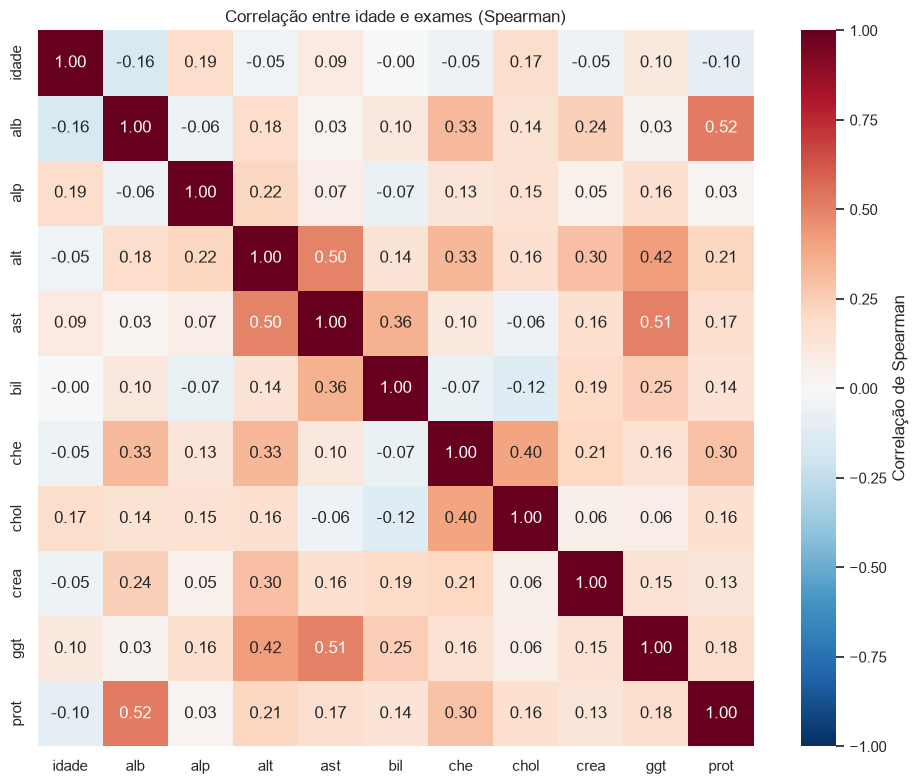

In [24]:
corr = df[config.COLS_QUANTITATIVAS].corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'label': 'Correlação de Spearman'})
ax.set_title('Correlação entre idade e exames (Spearman)')
fig.tight_layout()
salvar(fig, 'eda_correlacao_spearman')
plt.show()

### Quantitativa × qualitativa (razão de correlação η)

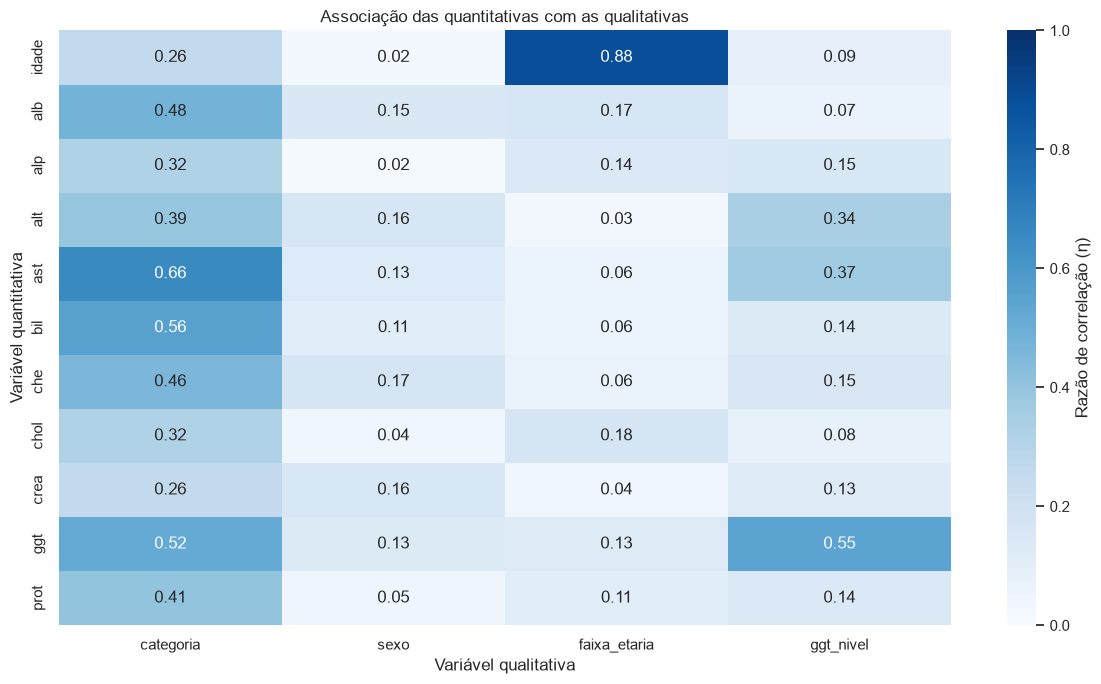

In [25]:
def razao_correlacao(categorias, valores):
    grupos = valores.groupby(categorias, observed=True)
    media = valores.mean()
    ss_entre = (grupos.count() * (grupos.mean() - media) ** 2).sum()
    ss_total = ((valores - media) ** 2).sum()
    return np.sqrt(ss_entre / ss_total)


matriz_eta = pd.DataFrame({
    cat: {num: razao_correlacao(df[cat], df[num]) for num in config.COLS_QUANTITATIVAS}
    for cat in QUALITATIVAS
})

fig, ax = plt.subplots(figsize=(2.5 * len(QUALITATIVAS) + 2, 7))
sns.heatmap(matriz_eta, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'Razão de correlação (η)'})
ax.set_title('Associação das quantitativas com as qualitativas')
ax.set_xlabel('Variável qualitativa')
ax.set_ylabel('Variável quantitativa')
fig.tight_layout()
salvar(fig, 'eda_razao_correlacao')
plt.show()

In [26]:
df.groupby('categoria', observed=True)[config.COLS_QUANTITATIVAS].median().round(2)

,idade,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
categoria,,,,,,,,,,,
Doador,47.0,42.2,66.70,23.10,24.8,6.9,8.35,5.40,78.00,21.40,72.20
Doador suspeito,55.0,21.6,106.00,49.20,46.7,4.9,5.33,4.30,52.00,83.00,47.80
Hepatite,37.0,43.5,36.95,18.30,47.2,13.0,9.51,5.06,72.25,45.55,73.65
Fibrose,51.0,41.0,45.20,34.00,70.0,13.0,8.59,4.64,71.40,72.20,76.10
Cirrose,56.0,33.0,76.83,5.65,92.9,34.0,3.42,3.87,68.50,96.35,69.95


In [27]:
df.groupby('sexo', observed=True)[config.COLS_QUANTITATIVAS].median().round(2)

,idade,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
sexo,,,,,,,,,,,
m,47.0,42.9,67.20,26.30,28.0,8.50,8.62,5.27,83.0,26.9,72.5
f,48.0,40.1,64.75,18.35,22.8,6.15,7.67,5.32,68.0,17.8,71.9


### Qualitativa × qualitativa

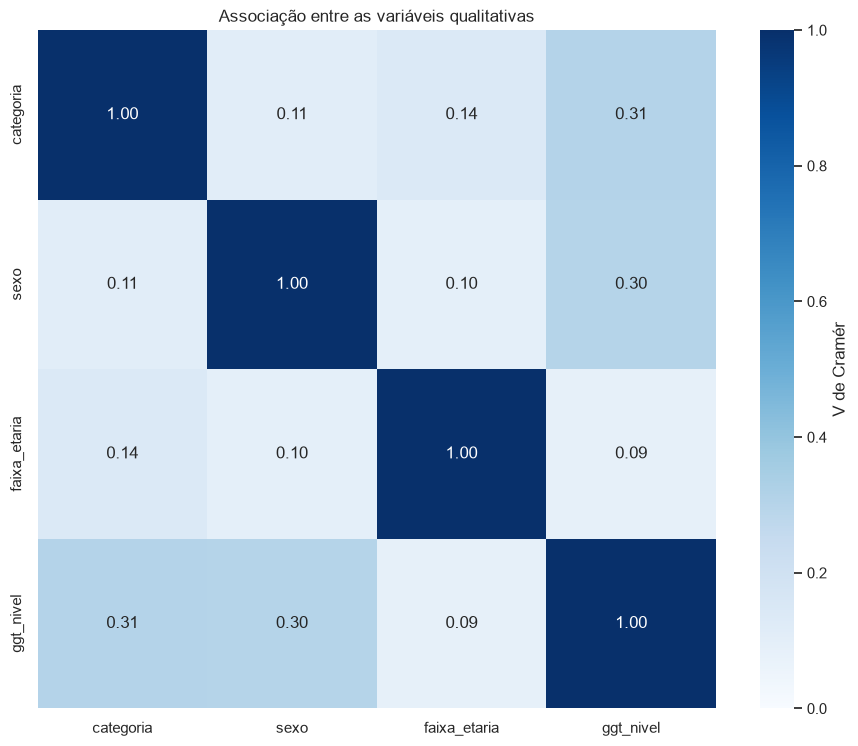

In [28]:
def cramers_v(x, y):
    tabela = pd.crosstab(x, y).to_numpy()
    n = tabela.sum()
    esperado = tabela.sum(axis=1, keepdims=True) @ tabela.sum(axis=0, keepdims=True) / n
    chi2 = ((tabela - esperado) ** 2 / esperado).sum()
    r, k = tabela.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


matriz_v = pd.DataFrame(
    [[cramers_v(df[a], df[b]) for b in QUALITATIVAS] for a in QUALITATIVAS],
    index=QUALITATIVAS, columns=QUALITATIVAS,
)

fig, ax = plt.subplots(figsize=(1.6 * len(QUALITATIVAS) + 3, 1.4 * len(QUALITATIVAS) + 2))
sns.heatmap(matriz_v, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True, ax=ax,
            cbar_kws={'label': 'V de Cramér'})
ax.set_title('Associação entre as variáveis qualitativas')
fig.tight_layout()
salvar(fig, 'eda_cramers_v')
plt.show()

In [29]:
pd.crosstab(df['categoria'], df['sexo'], normalize='index').mul(100).round(1)

sexo,m,f
categoria,,
Doador,59.7,40.3
Doador suspeito,85.7,14.3
Hepatite,83.3,16.7
Fibrose,61.9,38.1
Cirrose,66.7,33.3


### AST × GGT por diagnóstico

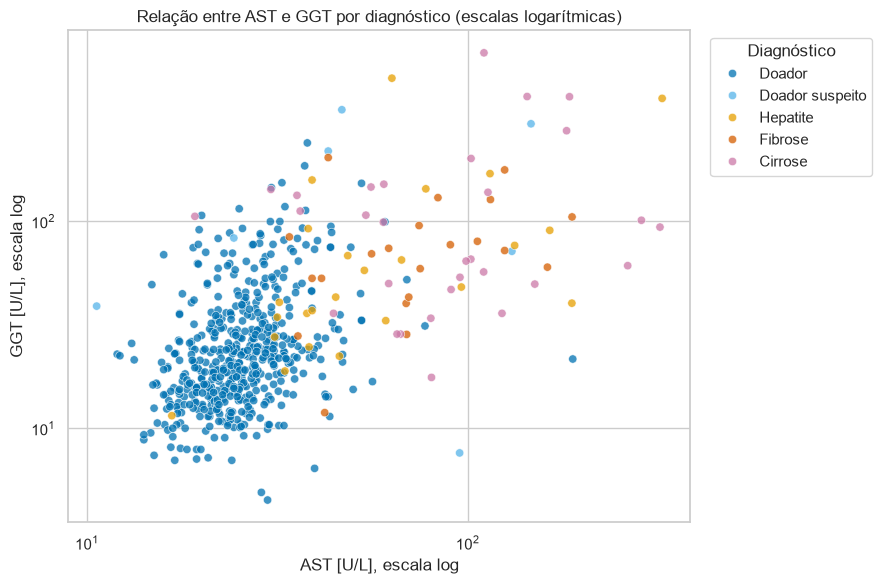

In [30]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x='ast', y='ggt', hue='categoria',
                hue_order=config.ORDEM_CATEGORIAS, palette=PALETA,
                alpha=0.75, ax=ax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Relação entre AST e GGT por diagnóstico (escalas logarítmicas)')
ax.set_xlabel(f"AST [{config.UNIDADES['ast']}], escala log")
ax.set_ylabel(f"GGT [{config.UNIDADES['ggt']}], escala log")
ax.legend(title='Diagnóstico', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
salvar(fig, 'eda_ast_ggt')
plt.show()

**Análise do grupo — relações:**

A maior concentração dos doadores fica na região inferior esquerda. Seus 50% centrais estão aproximadamente entre 21,1 e 29,8 em AST e entre 15,1 e 32 em GGT.

Os grupos com doença apresentam, em geral, valores centrais maiores. Hepatite tem medianas de AST e GGT de 47,2 e 45,55. Em fibrose, são 70 e 72,2. Em cirrose, 92,9 e 96,35.

A sobreposição aparece na região intermediária e nas caudas. Existem doadores com valores elevados e participantes com doença com valores menores. Hepatite, fibrose e cirrose também se misturam entre si. Assim, as duas variáveis mostram tendências de grupo, mas a posição de um ponto não determina sua categoria.

A associação geral pode ser descrita como positiva moderada, usando essa classificação como referência descritiva.

| Categoria | n | Spearman AST × GGT |
|---|---:|---:|
| Doadores | 533 | 0,381 |
| Doadores suspeitos | 7 | 0,214 |
| Hepatite | 24 | 0,624 |
| Fibrose | 21 | 0,440 |
| Cirrose | 30 | 0,089 |
| Amostra completa | 615 | 0,505 |

A relação varia bastante. Em cirrose, ela é praticamente nula nesta amostra. A estimativa dos suspeitos é especialmente instável por envolver sete registros.

Na base tratada, os maiores coeficientes positivos são:

- ALB × PROT — 0,517.
- AST × GGT — 0,505.
- ALT × AST — 0,497.
- ALT × GGT — 0,418.
- CHE × CHOL — 0,403.

As associações negativas de maior magnitude são fracas:

- Idade × ALB — −0,158.
- BIL × CHOL — −0,119.
- Idade × PROT — −0,100.

Entre as praticamente nulas estão idade × BIL, −0,005, ALB × AST, 0,028, e ALB × GGT, 0,034. Esses valores descrevem associação monotônica, e relações de outro formato podem passar despercebidas.

| Par | Spearman |
|---|---:|
| AST × GGT | 0,505 |
| AST × BIL | 0,356 |
| GGT × BIL | 0,247 |
| GGT × CHE | 0,156 |
| AST × CHE | 0,102 |
| BIL × CHE | −0,068 |

AST e GGT apresentam a associação mais evidente. CHE apresenta relações gerais fracas com os outros três, embora sua distribuição por diagnóstico mostre diferenças importantes.

Com a idade, as maiores associações são com ALP, 0,186, CHOL, 0,175, e ALB, −0,158. São relações fracas. A correlação com BIL é praticamente zero.

Os doadores representam aproximadamente 86,7% da amostra e têm grande influência nas correlações gerais. Esses coeficientes combinam a variação dentro dos grupos com diferenças entre eles. Por isso, a correlação da amostra completa precisa ser acompanhada das correlações por categoria, como mostra a comparação de AST × GGT.

## 6. Achados que viram as explanatórias

**Pergunta de pesquisa**

Como os perfis de AST, GGT, bilirrubina e colinesterase diferem entre doadores de sangue, doadores suspeitos e participantes classificados com hepatite, fibrose ou cirrose?

Escolhemos essa pergunta porque os exames apresentam diferenças entre as categorias e permitem investigar a separação e a sobreposição dos perfis laboratoriais.

**Classificação ou agrupamento**

Adotaremos a abordagem de classificação multiclasse, considerando `categoria` como variável-alvo e preservando as cinco categorias originais.

Essa escolha acompanha a estrutura do dataset, que possui rótulos conhecidos. A EDA e o dashboard serão utilizados para examinar como as características observadas se relacionam com essas categorias. A avaliação de um eventual classificador dependerá de treinamento e validação próprios.

**Público-alvo**

O público-alvo será formado por estudantes e pesquisadores de saúde e ciência de dados interessados na análise exploratória de exames laboratoriais.

O dashboard permitirá comparar os grupos, examinar distribuições e compreender as limitações da amostra, com filtros e gráficos acessíveis a usuários sem conhecimento de programação.

**Síntese para a resposta à pergunta de pesquisa**

Na amostra analisada, os perfis de AST, GGT, bilirrubina e colinesterase apresentam diferenças entre as categorias. As medianas de AST e GGT são maiores nos grupos de hepatite, fibrose e cirrose do que entre os doadores comuns. O grupo de cirrose também apresenta maior mediana de bilirrubina e menor mediana de colinesterase em relação aos doadores.

A distribuição dos tercis de GGT reforça essas diferenças, com maior concentração dos grupos com doença no tercil superior. A sobreposição dos valores individuais, o desequilíbrio entre as categorias e os grupos pequenos limitam as conclusões. Esses resultados descrevem a amostra e fundamentam a investigação da relação entre exames e categorias conhecidas.

**Doadores suspeitos na resposta**

Manteremos os suspeitos na pergunta, nas visualizações e na resposta final, explicitando seu tamanho de sete participantes. O perfil é misto:

| Exame | Suspeitos | Doadores | Hepatite | Fibrose | Cirrose |
|---|---:|---:|---:|---:|---:|
| AST — mediana | 46,7 | 24,8 | 47,2 | 70,0 | 92,9 |
| GGT — mediana | 83,0 | 21,4 | 45,55 | 72,2 | 96,35 |
| BIL — mediana | 4,9 | 6,9 | 13,0 | 13,0 | 34,0 |
| CHE — mediana | 5,33 | 8,35 | 9,51 | 8,59 | 3,425 |

Em AST e GGT, os suspeitos se aproximam mais dos grupos com doença. Em BIL, têm mediana menor que a dos doadores. Em CHE, ficam entre doadores e cirrose. Portanto, não apresentam um perfil uniformemente semelhante a uma única categoria.

Podemos descrever os valores observados, medianas e contagens desses sete registros. Por exemplo, seis dos sete estão no tercil superior de GGT. O tamanho reduzido limita generalizações e estimativas estáveis de associação. O rótulo disponível também não esclarece, por si só, o motivo da suspeita de cada participante.

## Registro do storytelling

**O que a exploração encontrou e onde**

- Visualização 1: forte desequilíbrio entre categorias, com 533 dos 615 registros pertencentes a doadores.
- Visualização 2 e seção 2 da EDA: ausência de ALP concentrada em determinados diagnósticos, chegando a 9 de 21 registros de fibrose.
- Visualização 3: doadores concentrados em valores menores de AST e GGT, enquanto os grupos com doença apresentam deslocamento e maior dispersão, com sobreposição.
- Visualização 4: associação positiva moderada entre AST e GGT, com Spearman de aproximadamente 0,505.
- Tabela de medianas por diagnóstico e boxplots da EDA: cirrose apresenta maiores medianas de AST, GGT e BIL e menor mediana de CHE que os doadores.
- Tabela de GGT discretizado por diagnóstico: o tercil superior reúne 25,3% dos doadores e 90% dos participantes com cirrose.

**Que história os dados contam**

A amostra reúne principalmente doadores de sangue e grupos menores com diferentes categorias de doença hepática. Os perfis laboratoriais diferem entre esses grupos, com maiores medianas de AST, GGT e BIL e menor mediana de CHE em cirrose quando comparada aos doadores. A sobreposição individual, os grupos pequenos e o padrão de ausência limitam a separação das categorias e a generalização dos resultados.

**Por que essa mensagem importa para o público**

Ela mostra como diferenças entre grupos podem coexistir com sobreposição individual. Também ensina que correlações gerais, percentuais e valores imputados precisam ser interpretados considerando o desequilíbrio da amostra e a qualidade dos dados.

**Qual técnica visual destaca a mensagem**

Na visualização 5, cirrose será destacada contra o contexto em cinza. Na visualização 6, o tercil superior será destacado pela intensidade do azul e pelo alinhamento dos segmentos.

**De quais exploratórias nasceram as explanatórias**

- Visualização 5: surgiu da visualização 3, que mostrou diferenças e sobreposição em AST e GGT, e dos boxplots e da tabela de medianas da EDA, que estenderam a comparação a BIL e CHE.
- Visualização 6: surgiu da visualização 3, que mostrou a distribuição desigual de GGT entre as categorias, e foi desenvolvida com a tabela de tercis da EDA.

### Atributos pré-atentivos das explanatórias

**Visualização 5**

**Mensagem.** Na amostra, cirrose apresenta medianas maiores de AST, GGT e BIL e menor de CHE que os doadores, com sobreposição dos valores individuais.

**O que o público precisa enxergar primeiro.** O contraste do perfil de cirrose com o dos doadores nos quatro exames, especialmente a inversão de direção em CHE.

**Destaque anterior.** Na visualização 5, as cinco categorias recebem cores distintas e disputam atenção. Falta uma hierarquia visual que conduza ao contraste principal.

**Atributo utilizado.** Contexto em cinza, mantendo cirrose na cor já utilizada para essa categoria. Os rótulos e as medianas devem permanecer legíveis em todos os grupos.

**Por que serve ao público.** Estudantes e pesquisadores precisam identificar o contraste principal e depois examinar a distribuição e as exceções. O destaque reduz a dependência da leitura repetida da legenda. Rótulos diretos, contagens e posição consistente complementam as cores e favorecem a leitura por pessoas com daltonismo.

**Visualização 6**

**Mensagem.** O tercil superior de GGT concentra uma proporção maior dos participantes com hepatite, fibrose e cirrose do que dos doadores.

**O que o público precisa enxergar primeiro.** A diferença no comprimento do segmento do tercil superior entre as categorias.

**Destaque anterior.** Na visualização 6, o código atual já utiliza três intensidades de azul. O tercil superior recebe o azul mais escuro e já tem destaque. O alinhamento pode ser melhorado colocando esse segmento no início de todas as barras, facilitando a comparação a partir de uma origem comum.

**Atributo utilizado.** Intensidade crescente de azul, com o tercil superior mais escuro, combinado ao posicionamento desse segmento no início das barras.

**Por que serve ao público.** Estudantes e pesquisadores precisam identificar o contraste principal e depois examinar a distribuição e as exceções. O destaque reduz a dependência da leitura repetida da legenda. Rótulos diretos, contagens e posição consistente complementam as cores e favorecem a leitura por pessoas com daltonismo.